# 1.5 Image classification, object detection and segmentation with pretrained models: workplace photos

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/1.5/1_5_one_image_workplace.ipynb)

Task 1.5 (part 1). Based on the lecturer's notebook **"Image classification, object detection, and image segmentation. With one picture"** (A. Laukaitis).
First I explain how the original works, then I run it on my own photos.

## How the original notebook works

Nothing is trained in this notebook. It downloads models from **TensorFlow Hub** that Google already trained on millions of images and uses them on one photo.

**Chapter 1. Image classification (2 models)**
1. Loads two **EfficientNetV2-S** classifiers (input 384×384):
   - model 1 was trained on **ImageNet-21k** (21,843 classes, very detailed, e.g. different kinds of churches),
   - model 2 was trained on ImageNet-21k and then fine-tuned on **ImageNet-1k** (1,000 common classes).
2. Downloads the class name lists for both models. The old ImageNet-21k label link stopped working, so it is taken from Hugging Face,
   and it checks that the number of labels matches the model output size.
3. Loads a photo from Wikimedia (Vilnius, Paris, tiger...), scales it to 0..1 and resizes it to 384×384 **with padding** so it doesn't get stretched.
4. `run_model_on_image` runs the model, applies `softmax` to get probabilities and prints the **top 4 classes**.
5. A slider cuts a 500×500 piece out of the photo and classifies only that piece. So we can see how the answer changes when the model sees just one detail.

**Chapter 2. Object detection**
6. Loads **SSD MobileNetV2** trained on **Open Images V4** (600 object classes). It returns boxes, class names and scores for up to 100 objects.
7. `draw_boxes` draws the best boxes with labels and percentages on the photo.

**Chapter 3. Image segmentation**
8. Loads **HRNet** trained on **ADE20K** (150 classes of things and "stuff" like wall, sky, floor, road).
   Segmentation gives a class probability **for every pixel**, so the output is one mask per class.
9. Shows all the masks in a grid, then puts 4 chosen masks on top of the photo.

## My photos

My CVMatch project is about jobs and candidates, so instead of city photos I use **workplace photos**: a job interview, coworking spaces and an old office.
I want to see what the pretrained models recognise in places where people work.
All photos are from Wikimedia Commons. I saved them in `data/photos/` (Wikimedia blocks too many downloads in a row, error 429):

| Name | Author / License |
|---|---|
| [Job interview](https://commons.wikimedia.org/wiki/File:Job_interview_0001.jpg) | bpsusf, CC BY 2.0 |
| [Coworking Berlin](https://commons.wikimedia.org/wiki/File:Coworking_Space_in_Berlin.jpg) | Deskmag, CC BY-SA 3.0 |
| [Coworking Columbus](https://commons.wikimedia.org/wiki/File:Coworking_Space_in_Columbus_Ohio.jpg) | Benlande, CC0 |
| [Office 1970s](https://commons.wikimedia.org/wiki/File:Office_workers_in_the_1970%27s_(9717154582).jpg) | Tyne & Wear Archives & Museums, no known restrictions |

I also add **one CV scan from my own document dataset** (`data/documents/test/resume/`, from RVL-CDIP, see task 1.4),
to see what models trained on ImageNet say about a CV. ImageNet has no "CV" class, so this shows why I need transfer learning in the next notebook.

What I changed: the photos, I classify **all photos in a loop** instead of one, and in segmentation I pick the 4 classes
that cover the biggest area automatically (the original used fixed mask numbers chosen for its own photo).
The models and helper functions are the same.

---
# Chapter 1. Image classification
With 2 models

In [1]:
import tensorflow as tf
import tensorflow_hub as hub

import os
import requests
from io import BytesIO
import numpy as np
from PIL import Image, ImageColor, ImageDraw, ImageFont
import matplotlib.pyplot as plt

### Helper functions (same as in the original)

In [2]:
def preprocess_image(image):
  image = np.array(image.convert('RGB'))
  img_reshaped = tf.reshape(image, [1, image.shape[0], image.shape[1], image.shape[2]])  # [batch, height, width, channels]
  image = tf.image.convert_image_dtype(img_reshaped, tf.float32)                        # 0..1 floats
  return image

def load_image_from_url(img_url):
  if os.path.exists(img_url):   # a local file from the repo
    return preprocess_image(Image.open(img_url))
  response = requests.get(img_url, headers={'User-agent': 'cvmatch-student-notebook/1.0'})
  response.raise_for_status()
  image = Image.open(BytesIO(response.content))
  return preprocess_image(image)

def load_image(image_url, image_size=256):
  img = load_image_from_url(image_url)
  img_raw = img
  img = tf.image.resize_with_pad(img, image_size, image_size)
  return img, img_raw

def show_image(image, title=''):
  plt.figure(figsize=(5, 5))
  plt.imshow(image[0], aspect='equal')
  plt.axis('off')
  plt.title(title)
  plt.show()

def run_model_on_image(p_image, p_classifier, p_classes):
  probabilities = tf.nn.softmax(p_classifier(p_image)).numpy()
  top_n = tf.argsort(probabilities, axis=-1, direction="DESCENDING")[0][:4].numpy()
  line = ''
  for i, class_index in enumerate(top_n):
    line += f'{i+1:2}) {class_index:5} - {p_classes[class_index]};   p = {probabilities[0][class_index]:.4f}\n'
  return line

### Load 2 models and class labels for them

In [3]:
input_size = 384
classifier = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_s/classification/2")
classifier2 = hub.load("https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_ft1k_s/classification/2")

labels_path = tf.keras.utils.get_file(
    'imagenet21k_wordnet_lemmas.txt',
    'https://huggingface.co/spaces/TexR6/AttentionMaps/resolve/main/labels/imagenet21k_wordnet_lemmas.txt')
classes = np.array(open(labels_path).read().splitlines())

labels_path2 = tf.keras.utils.get_file(
    'imagenet1k_wordnet_lemmas.txt',
    'https://storage.googleapis.com/download.tensorflow.org/data/ImageNetLabels.txt')
classes2 = np.array(open(labels_path2).read().splitlines())[1:]

# Check: number of labels must match the model output size
dummy = tf.zeros([1, input_size, input_size, 3])
print(len(classes), classifier(dummy).shape)
print(len(classes2), classifier2(dummy).shape)

21843 (1, 21843)


1000 (1, 1000)


---
## Two models and my photos

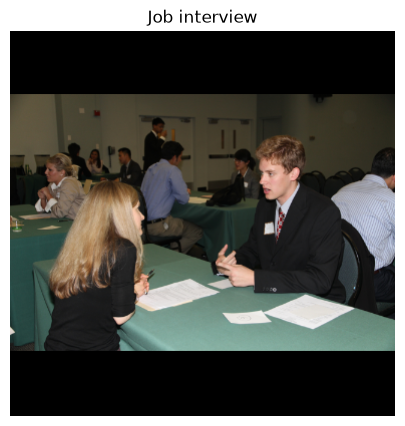

Model 1 (ImageNet-21k):


 1) 16920 - stakeholder;   p = 0.0662
 2)  8154 - lecture_room;   p = 0.0503
 3) 11937 - workroom;   p = 0.0311
 4) 11722 - war_room;   p = 0.0303

Model 2 (ImageNet-1k):
 1)   526 - desk;   p = 0.1997
 2)   834 - suit;   p = 0.1160
 3)   749 - quill;   p = 0.0538
 4)   916 - web site;   p = 0.0513



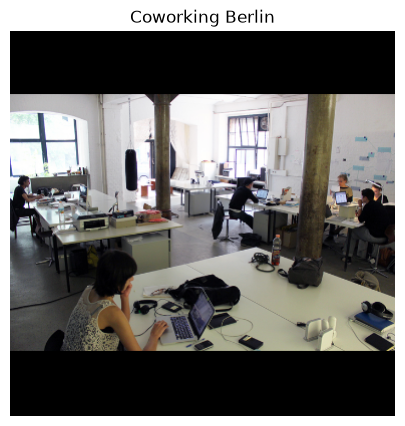

Model 1 (ImageNet-21k):


 1)  8847 - office, business_office;   p = 0.2508
 2) 11937 - workroom;   p = 0.2351
 3)  6235 - desk;   p = 0.0626
 4) 11870 - window;   p = 0.0505

Model 2 (ImageNet-1k):
 1)   526 - desk;   p = 0.8813
 2)   624 - library;   p = 0.0477
 3)   733 - pole;   p = 0.0045
 4)   916 - web site;   p = 0.0023



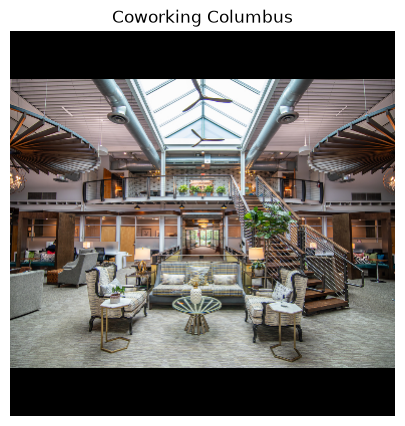

Model 1 (ImageNet-21k):


 1) 10436 - skylight, fanlight;   p = 0.2090
 2)  8533 - mezzanine, first_balcony;   p = 0.0488
 3)  9670 - railing, rail;   p = 0.0444
 4)  8532 - mezzanine, mezzanine_floor, entresol;   p = 0.0433

Model 2 (ImageNet-1k):
 1)   706 - patio;   p = 0.5261
 2)   580 - greenhouse;   p = 0.1633
 3)   884 - vault;   p = 0.0488
 4)   624 - library;   p = 0.0363



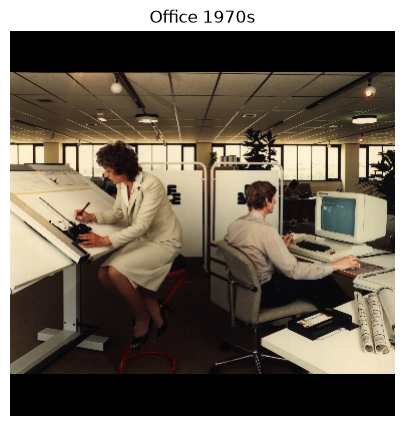

Model 1 (ImageNet-21k):


 1)  6440 - drafting_table, drawing_table;   p = 0.4718
 2) 11940 - workstation;   p = 0.0931
 3) 11670 - visual_display_unit, VDU;   p = 0.0344
 4)  5847 - computer, computing_machine, computing_device, data_processor, electronic_computer, information_processing_system;   p = 0.0277

Model 2 (ImageNet-1k):
 1)   617 - lab coat;   p = 0.4772
 2)   526 - desk;   p = 0.2061
 3)   527 - desktop computer;   p = 0.1159
 4)   624 - library;   p = 0.0173



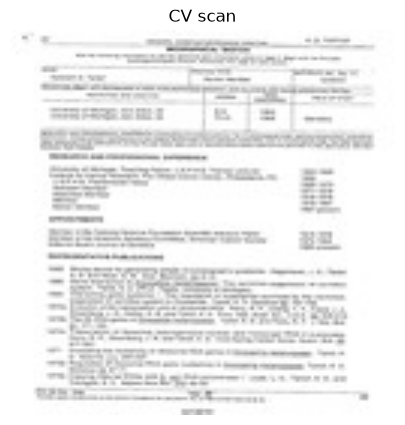

Model 1 (ImageNet-21k):
 1) 12214 - web_site, website, internet_site, site;   p = 0.1932
 2) 12222 - document, written_document, papers;   p = 0.0992
 3) 12180 - gazette;   p = 0.0757
 4) 12216 - portal_site, portal;   p = 0.0495

Model 2 (ImageNet-1k):


 1)   916 - web site;   p = 0.3729
 2)   922 - menu;   p = 0.3173
 3)   918 - crossword puzzle;   p = 0.0073
 4)   532 - dining table;   p = 0.0047



In [4]:
# The photos are in the repo: locally read from disk, in Colab from GitHub
def repo_file(path):
  if os.path.exists('../' + path):
    return '../' + path
  return 'https://raw.githubusercontent.com/jauniusc/cvmatch/main/' + path

images_for_test_map = {
    "Job interview": repo_file('data/photos/job_interview.jpg'),
    "Coworking Berlin": repo_file('data/photos/coworking_berlin.jpg'),
    "Coworking Columbus": repo_file('data/photos/coworking_columbus.jpg'),
    "Office 1970s": repo_file('data/photos/office_1970s.jpg'),
    "CV scan": repo_file('data/documents/test/resume/resume_0850.jpg'),   # one CV from my document dataset
}

for image_name, img_url in images_for_test_map.items():
  image, original_image = load_image(img_url, input_size)
  show_image(image, image_name)
  print("Model 1 (ImageNet-21k):")
  print(run_model_on_image(image, classifier, classes))
  print("Model 2 (ImageNet-1k):")
  print(run_model_on_image(image, classifier2, classes2))

---
## Let's cut a piece out of the photo and try again
I take the coworking photo from Columbus and cut out a square piece from it (in Colab these can be sliders, like in the original).

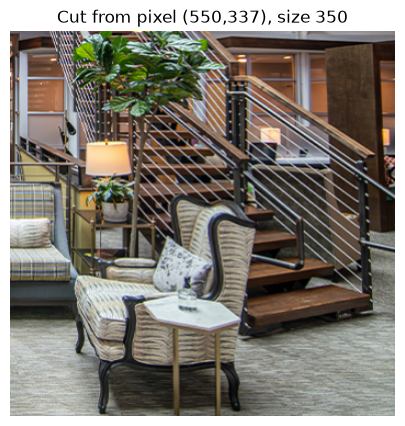

Model 1 (ImageNet-21k):
 1)  9670 - railing, rail;   p = 0.3011
 2)  5088 - broadloom;   p = 0.0477
 3)  8156 - ledger_board;   p = 0.0442
 4)  9671 - railing;   p = 0.0361

Model 2 (ImageNet-1k):


 1)   421 - bannister;   p = 0.8785
 2)   506 - coil;   p = 0.0245
 3)   539 - doormat;   p = 0.0069
 4)   706 - patio;   p = 0.0062



In [5]:
image_name = "Coworking Columbus"
image, original_image = load_image(images_for_test_map[image_name], input_size)

x = 55                     # left side of the cut, % of the width
y = 45                     # top side of the cut, % of the height
cut_size_in_pixels = 350

x_cord = int(original_image.shape[2] * x / 100)
y_cord = int(original_image.shape[1] * y / 100)
image_cut = original_image[:, y_cord:y_cord + cut_size_in_pixels, x_cord:x_cord + cut_size_in_pixels, :]
image_cut = tf.image.resize(image_cut, [input_size, input_size])

show_image(image_cut, f'Cut from pixel ({x_cord},{y_cord}), size {cut_size_in_pixels}')
print("Model 1 (ImageNet-21k):")
print(run_model_on_image(image_cut, classifier, classes))
print("Model 2 (ImageNet-1k):")
print(run_model_on_image(image_cut, classifier2, classes2))

---
# Chapter 2. Object detection

In [6]:
detector = hub.load("https://tfhub.dev/google/openimages_v4/ssd/mobilenet_v2/1").signatures['default']

INFO:tensorflow:Saver not created because there are no variables in the graph to restore


INFO:tensorflow:Saver not created because there are no variables in the graph to restore


### Helper functions (same as in the original)

In [7]:
def display_image(image):
  plt.figure(figsize=(10, 7))
  plt.grid(False)
  plt.axis('off')
  plt.imshow(image)
  plt.show()

def draw_bounding_box_on_image(image, ymin, xmin, ymax, xmax, color, font, thickness=4, display_str_list=()):
  draw = ImageDraw.Draw(image)
  im_width, im_height = image.size
  (left, right, top, bottom) = (xmin * im_width, xmax * im_width, ymin * im_height, ymax * im_height)
  draw.line([(left, top), (left, bottom), (right, bottom), (right, top), (left, top)], width=thickness, fill=color)

  display_str_heights = [font.getbbox(ds)[3] for ds in display_str_list]
  total_display_str_height = (1 + 2 * 0.05) * sum(display_str_heights)
  text_bottom = top if top > total_display_str_height else top + total_display_str_height
  for display_str in display_str_list[::-1]:
    bbox = font.getbbox(display_str)
    text_width, text_height = bbox[2], bbox[3]
    margin = np.ceil(0.05 * text_height)
    draw.rectangle([(left, text_bottom - text_height - 2 * margin), (left + text_width, text_bottom)], fill=color)
    draw.text((left + margin, text_bottom - text_height - margin), display_str, fill="black", font=font)
    text_bottom -= text_height - 2 * margin

def draw_boxes(image, boxes, class_names, scores, max_boxes=10, min_score=0.1):
  colors = list(ImageColor.colormap.values())
  try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/liberation/LiberationSansNarrow-Regular.ttf", 16)
  except IOError:
    font = ImageFont.load_default()
  for i in range(min(boxes.shape[0], max_boxes)):
    if scores[i] >= min_score:
      ymin, xmin, ymax, xmax = tuple(boxes[i])
      display_str = "{}: {}%".format(class_names[i].decode("ascii"), int(100 * scores[i]))
      color = colors[hash(class_names[i]) % len(colors)]
      image_pil = Image.fromarray(np.uint8(image)).convert("RGB")
      draw_bounding_box_on_image(image_pil, ymin, xmin, ymax, xmax, color, font, display_str_list=[display_str])
      np.copyto(image, np.array(image_pil))
  return image

def run_detector_2(detector, p_img, max_boxes=20):
  img = tf.cast(p_img[0] * 255, tf.uint8)
  result = detector(p_img)
  result = {key: value.numpy() for key, value in result.items()}
  print("Found %d objects." % len(result["detection_scores"]))
  image_with_boxes = draw_boxes(img.numpy(), result["detection_boxes"],
                                result["detection_class_entities"], result["detection_scores"], max_boxes=max_boxes)
  display_image(image_with_boxes)
  return result

### Detector

Found 100 objects.


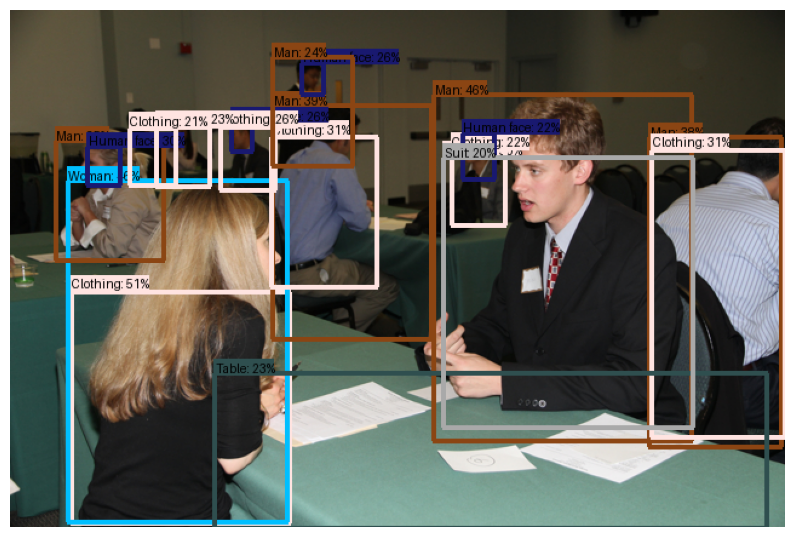

  Clothing: 0.51
  Clothing: 0.51
  Man: 0.47
  Woman: 0.47
  Man: 0.39
  Man: 0.39
  Man: 0.35
  Clothing: 0.32
  Clothing: 0.31
  Human face: 0.31


Found 100 objects.


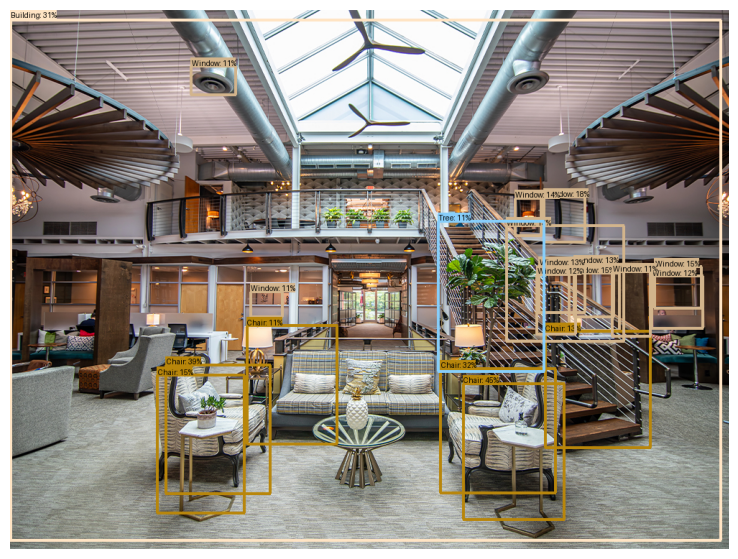

  Chair: 0.45
  Chair: 0.39
  Chair: 0.32
  Building: 0.31
  Window: 0.18
  Window: 0.16
  Chair: 0.15
  Window: 0.15
  Window: 0.14
  Chair: 0.14


In [8]:
for image_name in ["Job interview", "Coworking Columbus"]:
  _, original_image = load_image(images_for_test_map[image_name], input_size)
  detector_output = run_detector_2(detector, original_image)

  # The 10 most confident objects as text
  for name, score in list(zip(detector_output["detection_class_entities"], detector_output["detection_scores"]))[:10]:
    print(f"  {name.decode()}: {score:.2f}")

---
# Chapter 3. Image segmentation

In [9]:
import json

segmentation_ade20k_model = hub.load('https://tfhub.dev/google/HRNet/ade20k-hrnetv2-w48/1')

segmentation_labels_path = tf.keras.utils.get_file(
    'ade20k-id2label.json', 'https://huggingface.co/datasets/huggingface/label-files/raw/main/ade20k-id2label.json')
with open(segmentation_labels_path) as f:
  data = json.load(f)
classes_segmentation = ['background'] + list(data.values())
print(len(classes_segmentation), 'classes')

151 classes


(384, 384, 151)


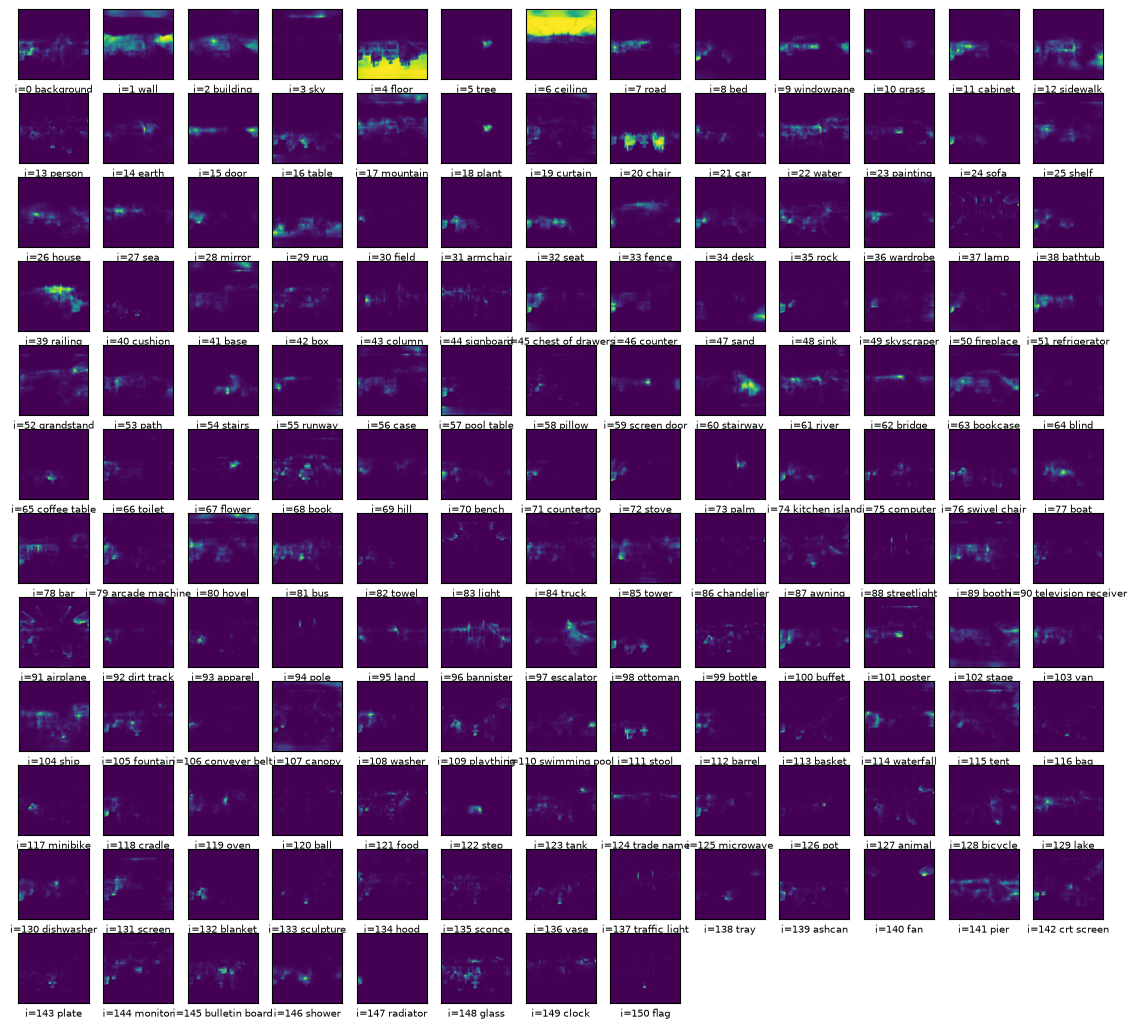

In [10]:
import math

image_name = "Coworking Columbus"
image, original_image = load_image(images_for_test_map[image_name], input_size)

predictions = segmentation_ade20k_model.predict(image)[0]   # shape (height, width, number of classes)
print(predictions.shape)

number_of_masks = predictions.shape[2]
plot_dim = math.ceil(math.sqrt(number_of_masks))

plt.figure(figsize=(14, 14))
for i in range(number_of_masks):
  plt.subplot(plot_dim, plot_dim, i + 1)
  plt.xticks([]); plt.yticks([]); plt.grid(False)
  plt.imshow(predictions[:, :, i])
  plt.xlabel(f'i={i} {classes_segmentation[i]}', fontsize=7)
plt.show()

### The 4 biggest classes on top of the photo
For every pixel I take the class with the highest score and count how many pixels each class got.

ceiling: 37.4% of pixels
floor: 31.7% of pixels
wall: 13.1% of pixels
chair: 7.2% of pixels


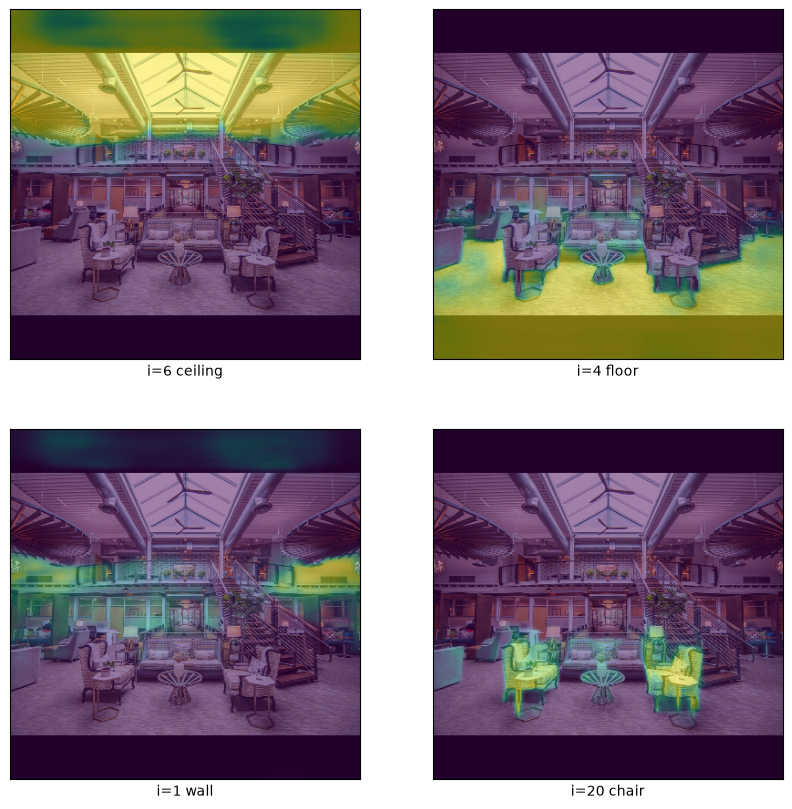

In [11]:
pixel_classes = np.argmax(predictions, axis=-1)
counts = np.bincount(pixel_classes.flatten(), minlength=number_of_masks)
top4 = [i for i in np.argsort(counts)[::-1] if i != 0][:4]   # skip 'background'

for i in top4:
  print(f"{classes_segmentation[i]}: {100 * counts[i] / pixel_classes.size:.1f}% of pixels")

plt.figure(figsize=(10, 10))
for k, i in enumerate(top4):
  plt.subplot(2, 2, k + 1)
  plt.xticks([]); plt.yticks([]); plt.grid(False)
  plt.imshow(image[0])
  plt.imshow(predictions[:, :, i], alpha=0.5)
  plt.xlabel(f'i={i} {classes_segmentation[i]}')
plt.show()

---
## Results and conclusions

| Photo | Model 1 (ImageNet-21k) | Model 2 (ImageNet-1k) |
|---|---|---|
| Job interview | stakeholder (0.07) | desk (0.20) |
| Coworking Berlin | office, business office (0.25) | desk (0.88) |
| Coworking Columbus | skylight (0.21) | patio (0.53) |
| Office 1970s | drafting table (0.47) | lab coat (0.48) |
| CV scan | web site (0.19), 2nd: document (0.10) | web site (0.37), 2nd: menu (0.32) |
| Columbus, cut piece | railing (0.30) | bannister (0.88) |

- The office photos are recognised well ("office", "desk", "workstation"). The Columbus space looks more like a lobby, so the answers are "skylight", "patio".
- Model 1 gives more exact names but lower probabilities, because it has 21,843 classes.
- The cut piece with the staircase gets "bannister" with 0.88, so the model describes what takes most of the picture.
- **ImageNet has no "CV" class**: for the CV scan the models only say "web site", "document", "menu". That's why the next notebook uses transfer learning.
- Detection finds the people, clothes, a suit and the table in the job interview photo, and chairs in the Columbus photo (scores under 0.5).
- Segmentation finds ceiling, floor, wall and chairs. The black stripes added by `resize_with_pad` are partly counted as ceiling and floor.